# 01 · FLUX 3 Image Klein on MPS — bf16 baseline (torch 2.14)

Runs **diffusers 0.43** `Flux3DistilledModularPipeline` (`black-forest-labs/flux-3-image-klein`, 16 steps, no CFG) on Apple Silicon in bf16.

Kernel: **FLUX3 (torch 2.14)** (`.venv-torch214`, `make kernels`).

Pipeline pieces (~39 GB bf16 in total):

| component | model | size |
|---|---|---|
| prompt upsampler | `flux-3-image-klein-pup` (Qwen3.5-9B) | 18.8 GB |
| text encoder | Qwen3-VL-4B | 8.9 GB |
| transformer | `Flux3Transformer2DModel` 5.6B | 11.1 GB |
| VAE | `AutoencoderKLFlux2` (fp32) | 0.3 GB |

The upsampler runs as its own stage (the documented "pop the `prompt_upsampler` block" pattern), so the expanded caption is saved and reused verbatim by notebook 02. Bf16 and FP8 then get exactly the same caption and seed.

> The repos are gated: accept the license at https://huggingface.co/black-forest-labs/flux-3-image-klein and make sure `HF_TOKEN` (or `hf auth login`) is set.

In [1]:
import json
import os
from pathlib import Path

os.environ.setdefault("PYTORCH_ENABLE_MPS_FALLBACK", "0")

import diffusers
import torch
import transformers
from IPython.display import display

from mps_flux_3_fp8.flux3 import (
    REPO_DISTILLED,
    free_mps,
    generate,
    load_pipeline,
    load_upsampler,
    module_gib,
    mps_memory,
    save,
)
from mps_flux_3_fp8.fp8 import probe_mps_fp8

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
OUT = ROOT / "outputs"
OUT.mkdir(exist_ok=True)
RESULTS = OUT / "results.json"


def record(name: str, seconds: float, transformer_gib: float, **extra) -> dict:
    """Append one run to outputs/results.json so the notebooks can compare across torch versions."""
    results = json.loads(RESULTS.read_text()) if RESULTS.exists() else {}
    results[name] = {
        "torch": torch.__version__,
        "seconds": round(seconds, 2),
        "transformer_gib": round(transformer_gib, 2),
        **extra,
    }
    RESULTS.write_text(json.dumps(results, indent=2))
    return results[name]


print(f"torch {torch.__version__} | diffusers {diffusers.__version__} | transformers {transformers.__version__}")
print("MPS available:", torch.backends.mps.is_available())
print(probe_mps_fp8())

/Users/njindal/build/mps_flux_3_fp8/.venv-torch214/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


W1117 16:07:47.299000 95991 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


torch 2.14.1 | diffusers 0.43.0 | transformers 5.23.0
MPS available: True
MpsFp8Support(torch_version='2.14.1', mps_available=True, float8_e4m3fn=False, scaled_mm=False, error='Undefined type Float8_e4m3fn')


In [2]:
REQUEST = "A man walking with his dog along a neighborhood sidewalk, afternoon sun"
SEED = 0
HEIGHT = WIDTH = 1024

## 1 · Prompt upsampling (Qwen3.5-9B on MPS)
Expand the short request into the full caption FLUX 3 is trained on, then free the 19 GB upsampler.

In [3]:
# Set False to skip the 18.8 GB upsampler and use a hand-written full caption instead.
USE_UPSAMPLER = True
FALLBACK_CAPTION = (
    "Full-color outdoor photograph, eye-level medium-wide shot in late afternoon sunlight, showing a man walking his "
    "dog along a neighborhood sidewalk. The low sun shines from the upper right, casting long shadows across the "
    "pavement and lighting the man's face and clothing with warm side light. Slightly left of center, a white man in "
    "his thirties with fair skin, short brown hair, and light stubble walks toward frame-left at an easy pace. He "
    "wears a faded olive overshirt over a plain grey T-shirt, dark blue jeans, and worn brown leather shoes. Beside "
    "him on a red leash, a golden retriever with a slightly dusty coat trots with its tongue out. In the background, "
    "parked cars, a low brick wall and leafy street trees fall into soft shapes of green, red and grey."
)

if USE_UPSAMPLER:
    pup = load_upsampler(REPO_DISTILLED)
    print("after load:", mps_memory())
    caption = pup(prompt=REQUEST, output="prompt")
    del pup
    print("after free:", free_mps())
else:
    caption = FALLBACK_CAPTION
(OUT / "caption.txt").write_text(caption)
print(f"{len(caption.split())} words\n\n{caption}")

/Users/njindal/build/mps_flux_3_fp8/.venv-torch214/lib/python3.13/site-packages/huggingface_hub/utils/_validators.py:205: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


Loading weights:   0%|          | 0/760 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 760/760 [00:00<00:00, 10102.08it/s]

after load: allocated=17.56 GiB, driver=17.73 GiB


[transformers] `causal_conv1d_fn` is falling back to its reference PyTorch implementation because `causal_conv1d` is not installed. This is correct but much slower; install `causal_conv1d` for the optimized kernel.


[transformers] `chunk_gated_delta_rule` is falling back to its reference PyTorch implementation because `flash-linear-attention` is not installed. This is correct but much slower; install `flash-linear-attention` for the optimized kernel.


[transformers] `causal_conv1d_update` is falling back to its reference PyTorch implementation because `causal_conv1d` is not installed. This is correct but much slower; install `causal_conv1d` for the optimized kernel.


[transformers] `fused_recurrent_gated_delta_rule` is falling back to its reference PyTorch implementation because `flash-linear-attention` is not installed. This is correct but much slower; install `flash-linear-attention` for the optimized kernel.


after free: allocated=0.00 GiB, driver=0.00 GiB
259 words

Full-color outdoor photograph taken at eye level in warm afternoon sunlight, showing a man walking his dog along a neighborhood sidewalk. In the foreground, a white man in his thirties with fair skin, short brown hair, and light stubble walks from left to right near the center. He wears a faded navy T-shirt, tan chinos, and worn grey walking shoes, with a canvas key ring hanging from his belt. His left foot is lifted mid-step and his right hand holds a loose brown leather leash. Beside him, a medium-sized golden retriever walks with its head lowered toward the pavement, its golden coat catching the sunlight and its tail hanging behind it. The leash curves between the man’s hand and the dog’s red collar. Long shadows from both figures stretch diagonally across the concrete sidewalk toward the lower left. A narrow strip of grass borders the path, with dry leaves and a flattened paper cup near the curb. On the right, modest detach

## 2 · Load the pipeline without the upsampler (bf16, VAE fp32)

In [4]:
pipe = load_pipeline(REPO_DISTILLED, with_upsampler=False)
print(pipe.blocks)
print(f"transformer: {module_gib(pipe.transformer):.2f} GiB, text encoder: {module_gib(pipe.text_encoder):.2f} GiB")

The config attributes {'force_upcast': True} were passed to AutoencoderKLFlux2, but are not expected and will be ignored. Please verify your config.json configuration file.


Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 713/713 [00:00<00:00, 9936.17it/s]

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Fetching 2 files: 100%|██████████| 2/2 [00:00<00:00, 791.45it/s]

Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

Loading checkpoint shards: 100%|██████████| 2/2 [00:00<00:00, 43.42it/s]

2026-11-17 16:08:22,838 - mps_flux_3_fp8 - /Users/njindal/build/mps_flux_3_fp8/src/mps_flux_3_fp8/flux3.py:90 - INFO - Loaded black-forest-labs/flux-3-image-klein (upsampler=False) on mps: allocated=18.98 GiB, driver=19.68 GiB


Flux3DistilledAutoBlocks(
  Class: SequentialPipelineBlocks

  Description: Auto blocks that perform text-to-image and image-to-image generation using the step-distilled FLUX.3 model (16 steps, no classifier-free guidance). `prompt` goes through the prompt upsampler first; pop the `prompt_upsampler` step to encode it as given.
      
      Supported workflows:
        - `text2image`: requires `prompt`
        - `image_conditioned`: requires `prompt`, `image`


  Components:
      text_encoder (`Qwen3VLForConditionalGeneration`)
      tokenizer (`AutoProcessor`)
      image_processor (`Flux3ImageProcessor`)
      vae (`AutoencoderKLFlux2`)
      transformer (`Flux3Transformer2DModel`)
      scheduler (`FlowMatchEulerDiscreteScheduler`)

  Sub-Blocks:
    [0] text_encoder (Flux3DistilledTextEncoderStep)
       Description: Text Encoder step that generates text embeddings using Qwen3-VL to guide the generation with the step-distilled FLUX.3 model, which samples without classifier-free gui

## 3 · Generate (warm-up run, then the timed run)

  0%|          | 0/2 [00:00<?, ?it/s]

 50%|█████     | 1/2 [00:00<00:00,  7.23it/s]

100%|██████████| 2/2 [00:00<00:00, 13.67it/s]

2026-11-17 16:08:24,240 - mps_flux_3_fp8 - /Users/njindal/build/mps_flux_3_fp8/src/mps_flux_3_fp8/flux3.py:147 - INFO - Generated 512x512 in 1.4s (allocated=18.98 GiB, driver=21.82 GiB)


  0%|          | 0/16 [00:00<?, ?it/s]

 12%|█▎        | 2/16 [00:00<00:00, 19.86it/s]

100%|██████████| 16/16 [00:00<00:00, 83.99it/s]

2026-11-17 16:08:42,234 - mps_flux_3_fp8 - /Users/njindal/build/mps_flux_3_fp8/src/mps_flux_3_fp8/flux3.py:147 - INFO - Generated 1024x1024 in 18.0s (allocated=18.98 GiB, driver=30.23 GiB)


{'torch': '2.14.1', 'seconds': 17.99, 'transformer_gib': 10.34, 'memory': 'allocated=18.98 GiB, driver=30.23 GiB'}


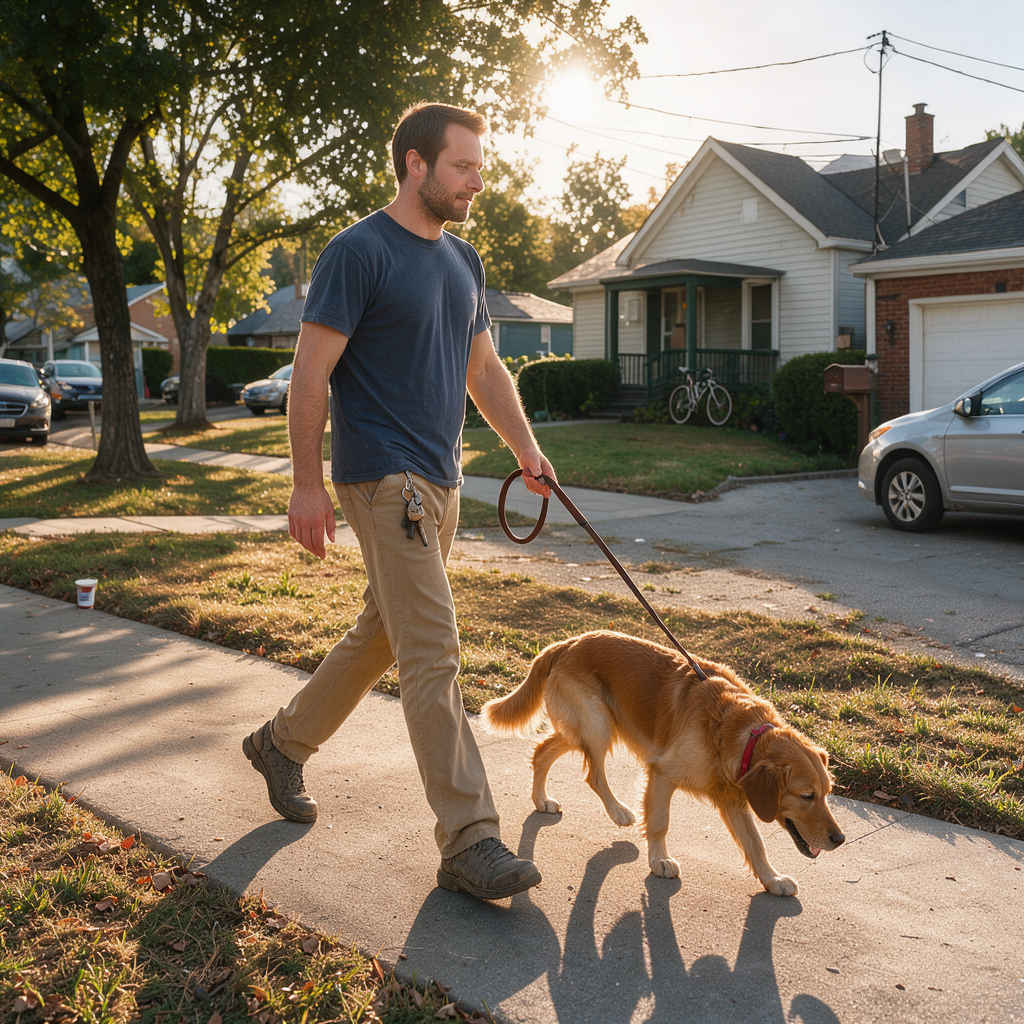

In [5]:
caption = (OUT / "caption.txt").read_text()
_ = generate(
    pipe, caption, seed=SEED, height=512, width=512, num_inference_steps=2
)  # warm-up: Metal kernel compilation
run = generate(pipe, caption, seed=SEED, height=HEIGHT, width=WIDTH)
save(run.image, OUT / "bf16_torch214.png")
print(record("bf16_torch214", run.seconds, module_gib(pipe.transformer), memory=str(run.memory)))
display(run.image)